# v4_ev — 전기차 등록대수 — 외생변수 민감도 분석

**질문.** 전기차 등록대수(보급 stock)를 외생변수로 넣으면 peak 전력수요 예측이 좋아질까?

**왜 분리해서 보나.** 본모델(ARIMAX **v3c**, MAE 2,668·MAPE 3.63%)은 이미 성능이 좋다.
전기차 변수는 ① 장기 추세항(`ip_total`·`pop_total`)과 **공선** 우려, ② 2010~2017이
사실상 0이라 **인위적 구조변화** 우려가 있어 본모델에 바로 넣지 않고, **서브기간 축소모델**로
증분 신호만 따로 검정한다 (robustness 전용, 본모델 불변).

- 결정 경위: `docs/research_log/2026-05-30_1100_*`, 검정 실행: `2026-05-30_1600_*`
- 산출 스크립트: `src/build_ev_stock.py`, `src/model_arimax_v4_ev.py`
- 이 노트북은 저장된 결과(`data/processed/...`)만 불러와 **시각적으로 요약**한다 (재학습 없음).


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
import seaborn as sns

warnings.filterwarnings("ignore")

# 한글 폰트 (eda/modeling.ipynb와 동일)
NOTO_PATH = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if NOTO_PATH.exists():
    font_manager.fontManager.addfont(str(NOTO_PATH))
KOR_FONT = "Noto Sans CJK JP"
mpl.rcParams["font.family"] = KOR_FONT
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", rc={"font.family": KOR_FONT})

# 프로젝트 루트 (notebooks/에서 실행해도 동작)
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"
print("ROOT:", ROOT)

ROOT: /home/jmlee/research/timeseries-final


## 1. "데이터는 길지만, 신호는 짧다"

등록현황 원자료는 2010-01부터 있지만, 한국 전기차는 2018년 전까진 사실상 0이다.
아래 연말 누적대수를 보면 **2017년까지 최종(72만대)의 ~1%**, 본격 ramp는 2018+ / 2021+.


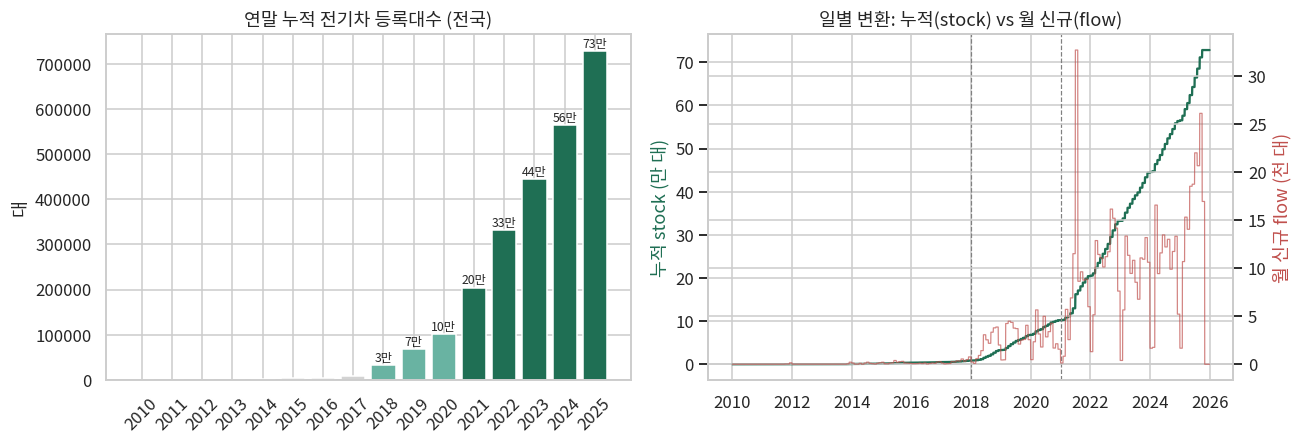

연말 누적: {2010: 5, 2011: 198, 2012: 232, 2013: 501, 2014: 1521, 2015: 3595, 2016: 4944, 2017: 8550, 2018: 32559, 2019: 67780, 2020: 102045, 2021: 204184, 2022: 332041, 2023: 444033, 2024: 563783, 2025: 728352}


In [2]:
ev = pd.read_csv(PROC / "ev_stock_daily_2010_2025.csv",
                 encoding="utf-8-sig", parse_dates=["tm"]).set_index("tm")
ye = ev["ev_stock"].groupby(ev.index.year).last()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
colors = ["lightgray" if y < 2018 else ("#69b3a2" if y < 2021 else "#1f6f54")
          for y in ye.index]
axes[0].bar(ye.index.astype(str), ye.values, color=colors)
axes[0].set_title("연말 누적 전기차 등록대수 (전국)")
axes[0].set_ylabel("대")
axes[0].tick_params(axis="x", rotation=45)
axes[0].axhline(0, color="k", lw=0.5)
for y, v in ye.items():
    if v > 20000:
        axes[0].text(str(y), v + 8000, f"{v/1e4:.0f}만", ha="center", fontsize=8)

# 일별 stock & flow
ax2 = axes[1]
ax2.plot(ev.index, ev["ev_stock"] / 1e4, color="#1f6f54", label="누적 stock")
ax2.set_ylabel("누적 stock (만 대)", color="#1f6f54")
ax2b = ax2.twinx()
ax2b.plot(ev.index, ev["ev_flow"] / 1e3, color="#c0504d", lw=0.8, alpha=0.7, label="월 신규 flow")
ax2b.set_ylabel("월 신규 flow (천 대)", color="#c0504d")
ax2.set_title("일별 변환: 누적(stock) vs 월 신규(flow)")
for x in [2018, 2021]:
    ax2.axvline(pd.Timestamp(f"{x}-01-01"), color="gray", ls="--", lw=0.8)
plt.tight_layout()
plt.show()

print("연말 누적:", {int(y): int(v) for y, v in ye.items()})

**색 구분**: 회색=2010~2017(바닥, 무신호), 연녹=2018~2020, 진녹=2021~.
단조 증가 S-curve → `pop_total`·SARIMA 적분추세와 거의 같은 모양(= 공선 위험).

## 2. 민감도 분석 설계

본모델 v3c와 **동일 차수**`(1,1,2)(1,1,1,7)`·log 타깃·평가 2025로 맞추고,
외생 14개(v3c)를 baseline으로 둔 뒤 EV 변수만 추가한다.

| 축 | 값 |
|---|---|
| 학습 시작연도 (window) | 2010~ / 2018~ / 2021~ (종료 2024, 평가 2025 고정) |
| EV 변수형태 (variant) | baseline(없음) / +ev_stock(누적) / +ev_flow(월 신규) |

→ 3×3 = 9개 모델. 결과는 `model_arimax_v4_ev.py`가 산출한 CSV를 불러온다.


In [3]:
res = pd.read_csv(PROC / "arimax" / "ev_sensitivity_results.csv", encoding="utf-8-sig")
show = ["window", "variant", "n_train", "AIC", "MAE_2025", "MAPE_2025_%",
        "ev_coef", "ev_p", "ev_VIF", "dAIC_vs_base", "dMAE_vs_base"]
res[show].round(3)

,window,variant,n_train,AIC,MAE_2025,MAPE_2025_%,ev_coef,ev_p,ev_VIF,dAIC_vs_base,dMAE_vs_base
0,2010~2024,baseline,5479,-23830.960,2667.510,3.630,NaN,NaN,NaN,0.000,0.000
1,2010~2024,+ev_stock,5479,-23828.499,2720.288,3.684,-0.013,0.694,1.020,2.461,52.778
2,2010~2024,+ev_flow,5479,-23829.125,2642.029,3.600,0.001,0.727,1.078,1.836,-25.481
3,2018~2024,baseline,2557,-11001.197,2346.316,3.166,NaN,NaN,NaN,0.000,0.000
4,2018~2024,+ev_stock,2557,-10998.728,2061.220,2.879,0.115,0.006,16.423,2.468,-285.096
5,2018~2024,+ev_flow,2557,-10989.249,2345.997,3.173,-0.001,0.558,1.951,11.948,-0.319
6,2021~2024,baseline,1461,-6350.615,2123.329,2.927,NaN,NaN,NaN,0.000,0.000
7,2021~2024,+ev_stock,1461,-6351.695,2042.736,2.876,0.046,0.205,11.605,-1.080,-80.593
8,2021~2024,+ev_flow,1461,-6347.249,2164.881,2.991,-0.001,0.666,1.482,3.366,41.551


## 3. 결과 시각화 — baseline 대비 개선폭과 공선성

왼쪽: **ΔMAE**(0보다 작아야 개선). 오른쪽: **VIF**(10 넘으면 추세와 심각한 공선 → 계수 불신).
EV가 추가된 variant(stock/flow)만 표시.


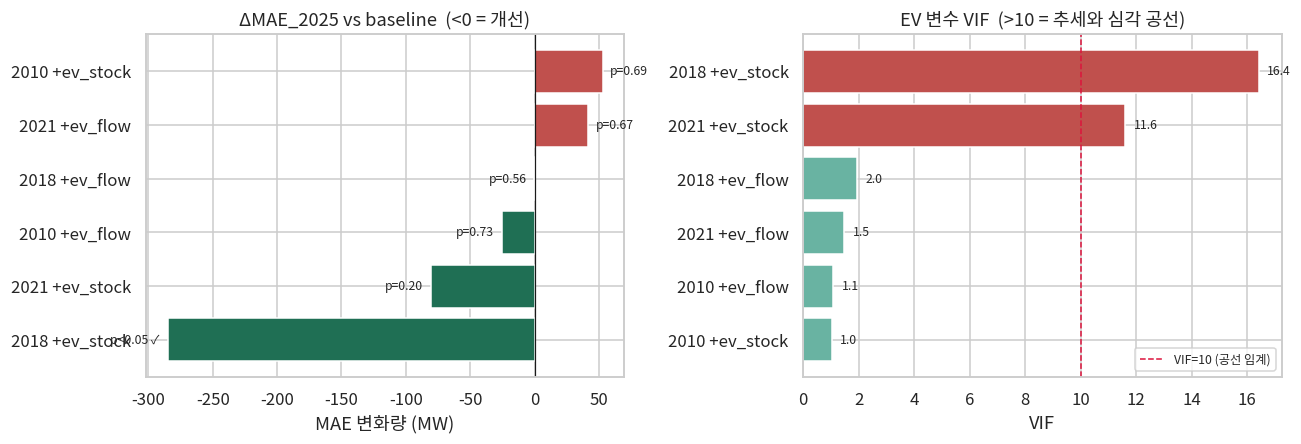

In [4]:
ev_rows = res[res["variant"] != "baseline"].copy()
ev_rows["lab"] = ev_rows["window"].str[:4] + " " + ev_rows["variant"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# (1) ΔMAE
order = ev_rows.sort_values("dMAE_vs_base")
bar_c = ["#1f6f54" if v < 0 else "#c0504d" for v in order["dMAE_vs_base"]]
axes[0].barh(order["lab"], order["dMAE_vs_base"], color=bar_c)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title("ΔMAE_2025 vs baseline  (<0 = 개선)")
axes[0].set_xlabel("MAE 변화량 (MW)")
for y, (v, p) in enumerate(zip(order["dMAE_vs_base"], order["ev_p"])):
    sig = "p<0.05 ✓" if p < 0.05 else f"p={p:.2f}"
    axes[0].text(v + (6 if v >= 0 else -6), y, sig, va="center",
                 ha="left" if v >= 0 else "right", fontsize=8)

# (2) VIF
order2 = ev_rows.sort_values("ev_VIF")
bar_c2 = ["#c0504d" if v >= 10 else "#69b3a2" for v in order2["ev_VIF"]]
axes[1].barh(order2["lab"], order2["ev_VIF"], color=bar_c2)
axes[1].axvline(10, color="crimson", ls="--", lw=1, label="VIF=10 (공선 임계)")
axes[1].set_title("EV 변수 VIF  (>10 = 추세와 심각 공선)")
axes[1].set_xlabel("VIF")
axes[1].legend(loc="lower right", fontsize=8)
for y, v in enumerate(order2["ev_VIF"]):
    axes[1].text(v + 0.3, y, f"{v:.1f}", va="center", fontsize=8)

plt.tight_layout()
plt.show()

## 4. 판정 — 4조건 동시 충족 여부

증분 신호를 **인정**하려면 네 가지가 **동시에** 성립해야 한다:
`ΔAIC<0` (정보기준 개선) · `ΔMAE<0` (예측 개선) · `EV p<0.05` (유의) · `VIF<10` (공선 아님).


In [5]:
chk = ev_rows.copy()
chk["ΔAIC<0"]  = chk["dAIC_vs_base"] < 0
chk["ΔMAE<0"]  = chk["dMAE_vs_base"] < 0
chk["p<0.05"]  = chk["ev_p"] < 0.05
chk["VIF<10"]  = chk["ev_VIF"] < 10
chk["인정?"]   = chk[["ΔAIC<0", "ΔMAE<0", "p<0.05", "VIF<10"]].all(axis=1)

def mark(b): return "✓" if b else "✗"
disp = pd.DataFrame({
    "window": chk["window"], "variant": chk["variant"],
    "ΔAIC<0": chk["ΔAIC<0"].map(mark), "ΔMAE<0": chk["ΔMAE<0"].map(mark),
    "p<0.05": chk["p<0.05"].map(mark), "VIF<10": chk["VIF<10"].map(mark),
    "→ 증분신호 인정": chk["인정?"].map(lambda b: "✅ 인정" if b else "❌ 기각"),
})
print(disp.to_string(index=False))
print(f"\n인정된 조합: {int(chk['인정?'].sum())} / {len(chk)}")

   window   variant ΔAIC<0 ΔMAE<0 p<0.05 VIF<10 → 증분신호 인정
2010~2024 +ev_stock      ✗      ✗      ✗      ✓      ❌ 기각
2010~2024  +ev_flow      ✗      ✓      ✗      ✓      ❌ 기각
2018~2024 +ev_stock      ✗      ✓      ✓      ✗      ❌ 기각
2018~2024  +ev_flow      ✗      ✓      ✗      ✓      ❌ 기각
2021~2024 +ev_stock      ✓      ✓      ✗      ✗      ❌ 기각
2021~2024  +ev_flow      ✗      ✗      ✗      ✓      ❌ 기각

인정된 조합: 0 / 6


## 결론

**6개 EV 조합 중 4조건을 모두 만족하는 것은 0개.** 가장 그럴듯한 케이스도 함정이 있다:

- **2018~ +stock**: MAE −285·p=0.006로 솔깃하지만 **VIF 16.4** — 추세항과 심각 공선이라
  계수가 불안정 분산으로만 식별되고, AIC는 오히려 악화(파라미터 페널티를 못 이김).
- **2021~ +stock**: AIC·MAE 미세 개선이나 **p=0.205(무의미)** + VIF 11.6.
- **flow(월 신규)**: 전 구간 무신호(p>0.5). 보급 '속도'에 일별 peak가 반응한다는 증거 없음.

→ 전기차 변수는 **본모델(v3c)에 넣지 않는다.** "신산업 동인은 검토했으나 추세 공선으로
독립 신호가 식별되지 않아 `ip_total`로 간접 포착"이 최종 입장이다. (본모델 코드·노트북 불변)
